# Grupo: Lucia Formenti y Juan Cruz Montero

# TP: Anatomía de una CNN con Fashion-MNIST  
## Notebook esqueleto para completar

Notebook ya estructurado en celdas. Cada celda de código tiene marcadores `[COMPLETAR AQUÍ]` donde se debe escribir o modificar código. Las celdas de texto indican dónde responder las preguntas.

***

### Celda 1 – Imports y configuración

```python
# =============================================================================
# TP: Anatomía de una CNN con Fashion-MNIST
# =============================================================================

import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

# [COMPLETAR AQUÍ]
# Si hace falta, instalá o importá alguna librería adicional que necesites
# (por ejemplo, sklearn para métricas avanzadas)
```

***

### Celda 2 – Carga del dataset

```python
# -----------------------------------------------------------------------------
# 1. Carga del dataset Fashion-MNIST
# -----------------------------------------------------------------------------

# [COMPLETAR AQUÍ]
# Cargar el dataset usando tf.keras.datasets.fashion_mnist
# Asignar a: (x_train, y_train), (x_test, y_test)

(x_train, y_train), (x_test, y_test) = ...

# Verificar shapes
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)
```

***

### Celda 3 – Preprocesamiento

```python
# -----------------------------------------------------------------------------
# 2. Preprocesamiento de las imágenes
# -----------------------------------------------------------------------------

# [COMPLETAR AQUÍ]
# 1. Agregar dimensión de canal para pasar de (28, 28) a (28, 28, 1)
# 2. Escalar los valores a [0, 1] dividiendo por 255.0

x_train = ...
x_test = ...

print("x_train shape con canal:", x_train.shape)

# Nombres de las clases (no modificar)
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
```

***

### Celda 4 – Visualización de ejemplos (opcional pero recomendada)

```python
# -----------------------------------------------------------------------------
# 3. Visualización de ejemplos del dataset
# -----------------------------------------------------------------------------

plt.figure(figsize=(12, 4))

# [COMPLETAR AQUÍ]
# Mostrar 10 imágenes de x_train con sus respectivas etiquetas (class_names[y_train[i]])
# Usar plt.subplot, plt.imshow, plt.title y plt.axis('off')

for i in range(10):
    ...

plt.tight_layout()
plt.show()
```

***

### Celda 5 – Construcción del modelo CNN

```python
# -----------------------------------------------------------------------------
# 4. Construcción del modelo CNN
# -----------------------------------------------------------------------------

# [COMPLETAR AQUÍ]
# Definir el modelo usando models.Sequential()
# El modelo debe incluir:
# - Input o input_shape (28, 28, 1)
# - Al menos 1 bloque: Conv2D + ReLU + MaxPooling2D
# - Dropout
# - Flatten
# - Dense intermedia con ReLU (recomendada)
# - Dense de salida con 10 unidades y activación 'softmax'

model = models.Sequential([
    # Capa de entrada + primera convolución
    layers.Conv2D(
        filters=...,
        kernel_size=(..., ...),
        activation='relu',
        input_shape=(..., ..., ...)
    ),
    
    # Pooling
    layers.MaxPooling2D(pool_size=(..., ...)),
    
    # Segunda convolución (recomendada)
    layers.Conv2D(
        filters=...,
        kernel_size=(..., ...),
        activation='relu'
    ),
    
    # Segundo pooling
    layers.MaxPooling2D(pool_size=(..., ...)),
    
    # Regularización (Dropout)
    layers.Dropout(...),
    
    # Vectorización
    layers.Flatten(),
    
    # Capa densa intermedia
    layers.Dense(..., activation='relu'),
    
    # Capa de salida (10 clases)
    layers.Dense(..., activation='softmax')
])

# Ver resumen del modelo
model.summary()
```

***

### Celda 6 – Compilación del modelo

```python
# -----------------------------------------------------------------------------
# 5. Compilación del modelo
# -----------------------------------------------------------------------------

# [COMPLETAR AQUÍ]
# Compilar el modelo con:
# - optimizer: 'adam'
# - loss: 'sparse_categorical_crossentropy' (porque y_train son enteros 0..9)
# - metrics: ['accuracy']

model.compile(
    optimizer=...,
    loss=...,
    metrics=[...]
)
```

***

### Celda 7 – Entrenamiento

```python
# -----------------------------------------------------------------------------
# 6. Entrenamiento del modelo
# -----------------------------------------------------------------------------

# [COMPLETAR AQUÍ]
# Entrenar el modelo con model.fit()
# - epochs: entre 10 y 20
# - batch_size: 32 o 64
# - validation_split: 0.1 (usar 10% de x_train para validación)

history = model.fit(
    ...,  # x_train
    ...,  # y_train
    epochs=...,
    batch_size=...,
    validation_split=...,
    verbose=1
)
```

***

### Celda 8 – Evaluación en test

```python
# -----------------------------------------------------------------------------
# 7. Evaluación en el conjunto de test
# -----------------------------------------------------------------------------

# [COMPLETAR AQUÍ]
# Evaluar el modelo en (x_test, y_test) y obtener loss y accuracy

test_loss, test_acc = model.evaluate(..., ..., verbose=0)

print(f"Test accuracy: {test_acc:.4f}")
```

***

### Celda 9 – Curvas de entrenamiento

```python
# -----------------------------------------------------------------------------
# 8. Visualización de curvas de entrenamiento
# -----------------------------------------------------------------------------

plt.figure(figsize=(12, 4))

# [COMPLETAR AQUÍ]
# Graficar:
# - Accuracy de entrenamiento y validación vs epoch (subplot 1)
# - Loss de entrenamiento y validación vs epoch (subplot 2)
# Usar history.history['accuracy'], history.history['val_accuracy'],
#      history.history['loss'], history.history['val_loss']

# Accuracy
plt.subplot(1, 2, 1)
...

# Loss
plt.subplot(1, 2, 2)
...

plt.tight_layout()
plt.show()
```

***

### Celda 10 – Predicciones y análisis de errores

```python
# -----------------------------------------------------------------------------
# 9. Predicciones y análisis de errores
# -----------------------------------------------------------------------------

# [COMPLETAR AQUÍ]
# 1. Obtener predicciones en x_test (probabilidades)
# 2. Convertir a clases con np.argmax
# 3. Comparar con y_test para obtener correctas e incorrectas

y_pred_proba = ...
y_pred = ...

correct = ...
incorrect = ...

# Visualizar 5 predicciones correctas y 5 incorrectas
plt.figure(figsize=(12, 4))

# 5 correctas
for i, idx in enumerate(np.where(correct)[0][:5]):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_test[idx].squeeze(), cmap='gray')
    plt.title(f"Real: {class_names[y_train[idx]]}\nPred: {class_names[y_pred[idx]]}")
    plt.axis('off')

# 5 incorrectas
for i, idx in enumerate(np.where(incorrect)[0][:5]):
    plt.subplot(2, 5, i+6)
    plt.imshow(x_test[idx].squeeze(), cmap='gray')
    plt.title(f"Real: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}", color='red')
    plt.axis('off')

plt.tight_layout()
plt.show()
```

> **Nota:** En el título de las imágenes correctas, asegurarse de usar `y_test[idx]` en lugar de `y_train[idx]`.

***

### Celda 11 – Respuestas teóricas (A. Sobre la arquitectura)

> **Instrucción:** Insertar una celda de texto debajo y responder.

**A. Sobre la arquitectura**

1. ¿Cuántas capas entrenables tiene tu modelo?  
   Usá `model.summary()` para contar las capas con parámetros (Conv2D y Dense). No incluyas pooling, dropout ni flatten.

2. ¿Cuál es la cantidad total de parámetros entrenables?  
   Indicá el número que aparece en `Total params` en el resumen del modelo.

3. Explicá con tus palabras qué hace cada una de estas capas en tu modelo:
   - Conv2D  
   - MaxPooling2D  
   - Dropout  
   - Flatten  
   - Dense (última capa)

4. ¿Por qué la última capa tiene 10 unidades y activación softmax?  
   Relacioná esto con la cantidad de clases del problema.

***

### Celda 12 – Respuestas teóricas (B. Sobre el entrenamiento)

> **Instrucción:** Insertar una celda de texto debajo y responder.

**B. Sobre el entrenamiento**

5. Observá las curvas de accuracy y loss vs epoch.  
   - ¿El accuracy de entrenamiento aumenta con las épocas?  
   - ¿El accuracy de validación sigue la misma tendencia?  
   - ¿Hay signos de sobreajuste (val_loss empieza a subir mientras train_loss sigue bajando)?

6. Si quisieras reducir el sobreajuste, ¿qué cambios podrías hacer en la arquitectura o en el entrenamiento?  
   Mencioná al menos dos ideas (por ejemplo: más dropout, menos capas, menos filtros, early stopping, data augmentation, etc.).

***

### Celda 13 – Respuestas teóricas (C. Sobre las predicciones)

> **Instrucción:** Insertar una celda de texto debajo y responder.

**C. Sobre las predicciones**

7. Observá los ejemplos de predicciones incorrectas que graficaste.  
   - ¿Las imágenes son difíciles de clasificar incluso para un humano?  
   - ¿Hay alguna clase que se confunda mucho con otra?  
   - Proponé una posible razón (similitud visual, poca cantidad de ejemplos, etc.).

8. Calculá la precisión por clase (opcional, más avanzado).  
   Podés usar:

   ```python
   from sklearn.metrics import classification_report

   print(classification_report(y_test, y_pred, target_names=class_names))
   ```

   - ¿Qué clases tienen mejor y peor desempeño?  
   - ¿Coincide esto con lo que observaste visualmente?

***

### Celda 14 – Experimentación (D. Opcional pero recomendada)

> **Instrucción:** Insertar una celda de código y una de texto debajo.

**D. Experimentación (opcional pero muy recomendada)**

9. Modificá la arquitectura y compará resultados.  
   Probá al menos una de estas variantes y comentá qué pasó con la precisión en test:
   - Agregar una capa Conv2D + MaxPooling2D adicional.
   - Cambiar la cantidad de filtros (por ejemplo, 16 → 32 → 64).
   - Cambiar el dropout (0.3, 0.5, 0.7).
   - Quitar la capa Dense intermedia y dejar solo Flatten → Softmax.

En una celda de código:

```python
# [COMPLETAR AQUÍ]
# Definir un nuevo modelo (model_v2) con la variante que elegiste
# Compilar y entrenar igual que antes
# Evaluar en test e imprimir la nueva precisión

model_v2 = models.Sequential([
    # ... completar arquitectura modificada ...
])

model_v2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_v2 = model_v2.fit(
    x_train, y_train,
    epochs=...,
    batch_size=...,
    validation_split=0.1,
    verbose=1
)

test_loss_v2, test_acc_v2 = model_v2.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy (modelo modificado): {test_acc_v2:.4f}")
```

En una celda de texto:

- Incluí el nuevo `model_v2.summary()` (puedes copiarlo como texto).
- Indicá la nueva precisión en test.
- Comentá brevemente si mejoró o empeoró y por qué creés que ocurrió eso.

***

### Celda 15 – Entrega

> **Instrucción:** Insertar una celda de texto.

**Entrega**

- Verificar que el notebook se pueda ejecutar de corrido (Runtime → Run all).
- Asegurarse de que todas las preguntas estén respondidas en celdas de texto.
- Guardar el notebook y entregar el archivo `.ipynb` o el link de Colab con permisos de visualización.

***


In [1]:
# =============================================================================
# TP: Anatomía de una CNN con Fashion-MNIST
# =============================================================================

import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

# Librerías adicionales para las métricas por clase y la matriz de confusión
from sklearn.metrics import classification_report, confusion_matrix

# Semilla fija para que los resultados sean reproducibles
tf.keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
# -----------------------------------------------------------------------------
# 1. Carga del dataset Fashion-MNIST
# -----------------------------------------------------------------------------

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# Verificar shapes
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)
y_test shape: (10000,)


In [3]:
# -----------------------------------------------------------------------------
# 2. Preprocesamiento de las imágenes
# -----------------------------------------------------------------------------

# 1. Agregar dimensión de canal: (28, 28) -> (28, 28, 1)
# 2. Escalar los valores a [0, 1]
x_train = x_train.reshape((-1, 28, 28, 1)).astype("float32") / 255.0
x_test = x_test.reshape((-1, 28, 28, 1)).astype("float32") / 255.0

print("x_train shape con canal:", x_train.shape)
print("x_test shape con canal: ", x_test.shape)
print("Valor mínimo y máximo de los píxeles:", x_train.min(), x_train.max())

# Nombres de las clases (no modificar)
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

x_train shape con canal: (60000, 28, 28, 1)
x_test shape con canal:  (10000, 28, 28, 1)
Valor mínimo y máximo de los píxeles: 0.0 1.0


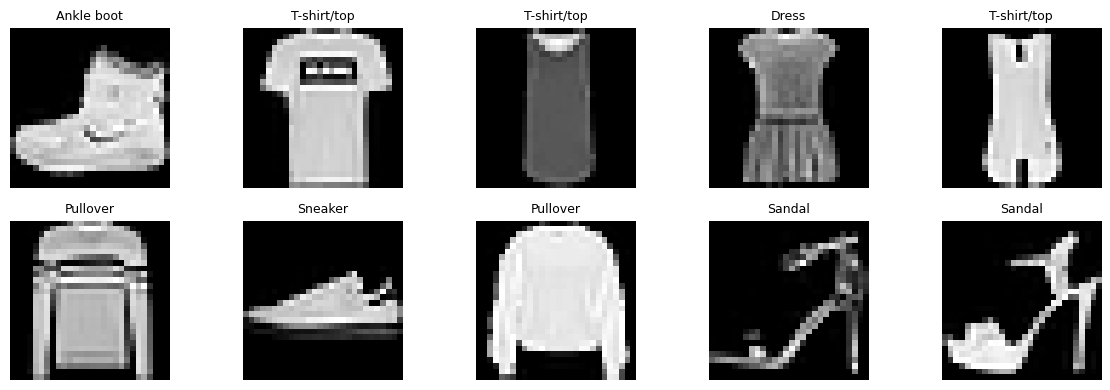

In [4]:
# -----------------------------------------------------------------------------
# 3. Visualización de ejemplos del dataset
# -----------------------------------------------------------------------------

plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train[i]], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
# -----------------------------------------------------------------------------
# 4. Construcción del modelo CNN
# -----------------------------------------------------------------------------

model = models.Sequential([
    # Primer bloque convolucional: 32 filtros 3x3
    layers.Conv2D(32, (3, 3), activation='relu',
                  padding='same', input_shape=(28, 28, 1)),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),

    # Segundo bloque convolucional: 64 filtros 3x3
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),

    # Vectorización
    layers.Flatten(),

    # Capa densa intermedia
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # Capa de salida (10 clases)
    layers.Dense(10, activation='softmax')
])

# Ver resumen del modelo
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# -----------------------------------------------------------------------------
# 5. Compilación del modelo
# -----------------------------------------------------------------------------

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',  # y_train son enteros 0..9
    metrics=['accuracy']
)

print("Modelo compilado.")

Modelo compilado.


In [7]:
# -----------------------------------------------------------------------------
# 6. Entrenamiento del modelo
# -----------------------------------------------------------------------------

history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,   # 10% de x_train se usa para validación
    verbose=1
)

Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 21s 14ms/step - accuracy: 0.7838 - loss: 0.6019 - val_accuracy: 0.8638 - val_loss: 0.3659
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8553 - loss: 0.4043 - val_accuracy: 0.8807 - val_loss: 0.3095
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8727 - loss: 0.3560 - val_accuracy: 0.8932 - val_loss: 0.2797
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8821 - loss: 0.3260 - val_accuracy: 0.8967 - val_loss: 0.2715
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8913 - loss: 0.3039 - val_accuracy: 0.9037 - val_loss: 0.2592
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8961 - loss: 0.2878 - val_accuracy: 0.9130 - val_loss: 0.2392
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9007 - loss: 0.2734 - val_accuracy: 0.9122 - val_loss: 0.2356
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9039 - loss: 0.2655 - val_accuracy: 

In [8]:
# -----------------------------------------------------------------------------
# 7. Evaluación en el conjunto de test
# -----------------------------------------------------------------------------

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss:     0.2239
Test accuracy: 0.9193


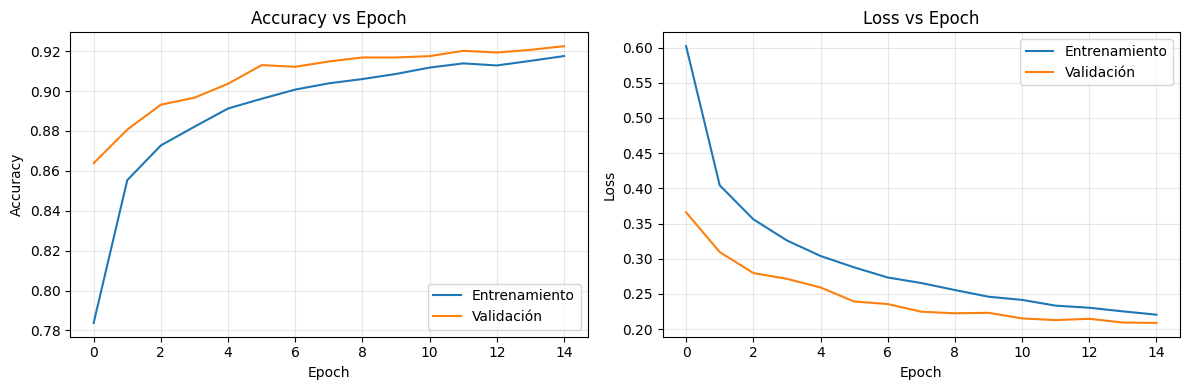

Accuracy final - entrenamiento: 0.9175
Accuracy final - validación:    0.9225
Loss final - entrenamiento:     0.2205
Loss final - validación:        0.2089
Mejor val_accuracy: 0.9225 (época 15)
Menor val_loss:     0.2089 (época 15)


In [9]:
# -----------------------------------------------------------------------------
# 8. Visualización de curvas de entrenamiento
# -----------------------------------------------------------------------------

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Accuracy vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Loss vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Valores finales, para usarlos en las respuestas
print(f"Accuracy final - entrenamiento: {history.history['accuracy'][-1]:.4f}")
print(f"Accuracy final - validación:    {history.history['val_accuracy'][-1]:.4f}")
print(f"Loss final - entrenamiento:     {history.history['loss'][-1]:.4f}")
print(f"Loss final - validación:        {history.history['val_loss'][-1]:.4f}")
print(f"Mejor val_accuracy: {max(history.history['val_accuracy']):.4f}"
      f" (época {int(np.argmax(history.history['val_accuracy'])) + 1})")
print(f"Menor val_loss:     {min(history.history['val_loss']):.4f}"
      f" (época {int(np.argmin(history.history['val_loss'])) + 1})")

Imagen de entrada:           (1, 28, 28, 1)
Salida de la 1ra Conv2D:     (1, 28, 28, 32)
Salida del MaxPooling2D:     (1, 14, 14, 32)
Clase real de la imagen:     Ankle boot


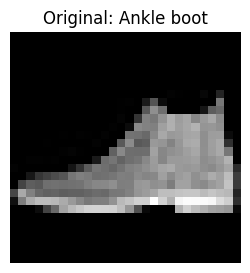

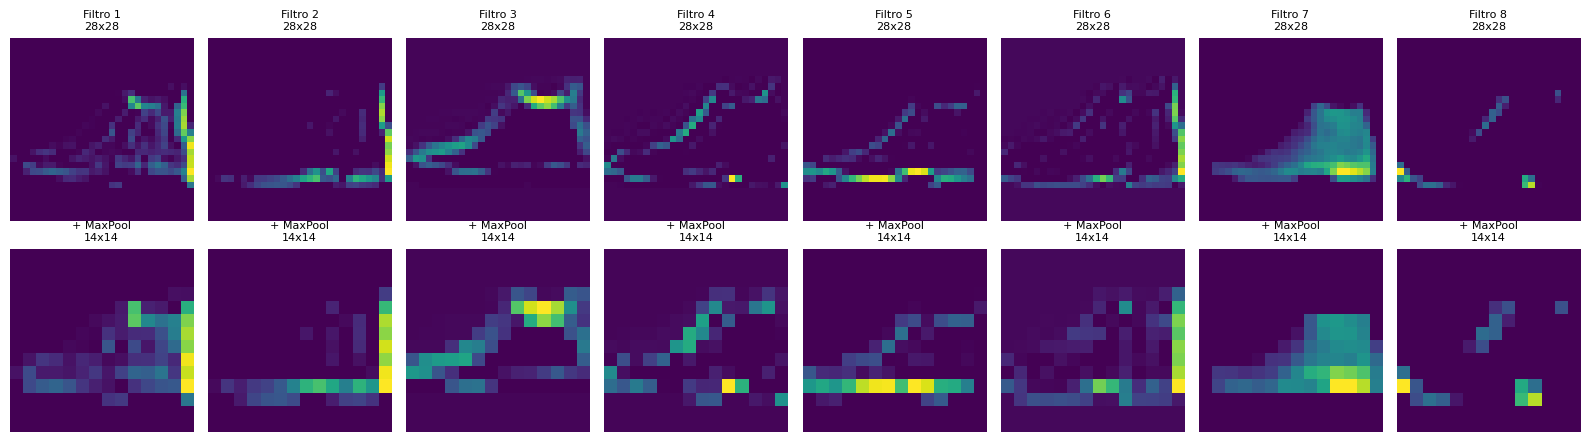

In [10]:
# Submodelos que comparten los pesos ya entrenados
solo_conv = models.Sequential(model.layers[:1])   # salida de la primera Conv2D
conv_pool = models.Sequential(model.layers[:2])   # salida después del MaxPooling2D

img = x_test[0:1]   # una imagen de test

mapas_conv = solo_conv.predict(img, verbose=0)    # (1, 28, 28, 32)
mapas_pool = conv_pool.predict(img, verbose=0)    # (1, 14, 14, 32)

print("Imagen de entrada:          ", img.shape)
print("Salida de la 1ra Conv2D:    ", mapas_conv.shape)
print("Salida del MaxPooling2D:    ", mapas_pool.shape)
print("Clase real de la imagen:    ", class_names[y_test[0]])

# Imagen original
plt.figure(figsize=(3, 3))
plt.imshow(img.squeeze(), cmap='gray')
plt.title(f"Original: {class_names[y_test[0]]}")
plt.axis('off')
plt.show()

# Primeros 8 mapas de características de la Conv2D y su versión tras el pooling
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i in range(8):
    axes[0, i].imshow(mapas_conv[0, :, :, i], cmap='viridis')
    axes[0, i].set_title(f"Filtro {i+1}\n28x28", fontsize=8)
    axes[0, i].axis('off')

    axes[1, i].imshow(mapas_pool[0, :, :, i], cmap='viridis')
    axes[1, i].set_title(f"+ MaxPool\n14x14", fontsize=8)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

Predicciones correctas:   9193 de 10000
Predicciones incorrectas: 807 de 10000


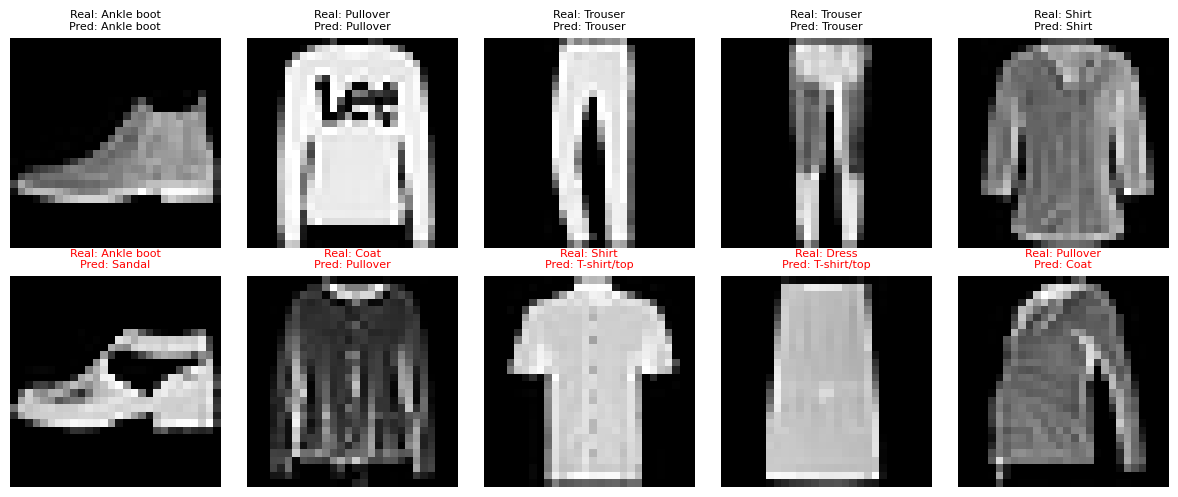

In [11]:
# -----------------------------------------------------------------------------
# 9. Predicciones y análisis de errores
# -----------------------------------------------------------------------------

# 1. Probabilidades para cada clase
y_pred_proba = model.predict(x_test, verbose=0)

# 2. Clase predicha = la de mayor probabilidad
y_pred = np.argmax(y_pred_proba, axis=1)

# 3. Comparación con las etiquetas reales
correct = (y_pred == y_test)
incorrect = ~correct

print(f"Predicciones correctas:   {correct.sum()} de {len(y_test)}")
print(f"Predicciones incorrectas: {incorrect.sum()} de {len(y_test)}")

# Visualizar 5 predicciones correctas y 5 incorrectas
plt.figure(figsize=(12, 5))

# 5 correctas
for i, idx in enumerate(np.where(correct)[0][:5]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx].squeeze(), cmap='gray')
    plt.title(f"Real: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=8)
    plt.axis('off')

# 5 incorrectas
for i, idx in enumerate(np.where(incorrect)[0][:5]):
    plt.subplot(2, 5, i + 6)
    plt.imshow(x_test[idx].squeeze(), cmap='gray')
    plt.title(f"Real: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=8, color='red')
    plt.axis('off')

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

 T-shirt/top      0.862     0.877     0.870      1000
     Trouser      0.990     0.989     0.989      1000
    Pullover      0.873     0.879     0.876      1000
       Dress      0.913     0.926     0.920      1000
        Coat      0.827     0.914     0.868      1000
      Sandal      0.987     0.990     0.989      1000
       Shirt      0.804     0.691     0.743      1000
     Sneaker      0.957     0.979     0.968      1000
         Bag      0.990     0.987     0.988      1000
  Ankle boot      0.985     0.961     0.973      1000

    accuracy                          0.919     10000
   macro avg      0.919     0.919     0.918     10000
weighted avg      0.919     0.919     0.918     10000



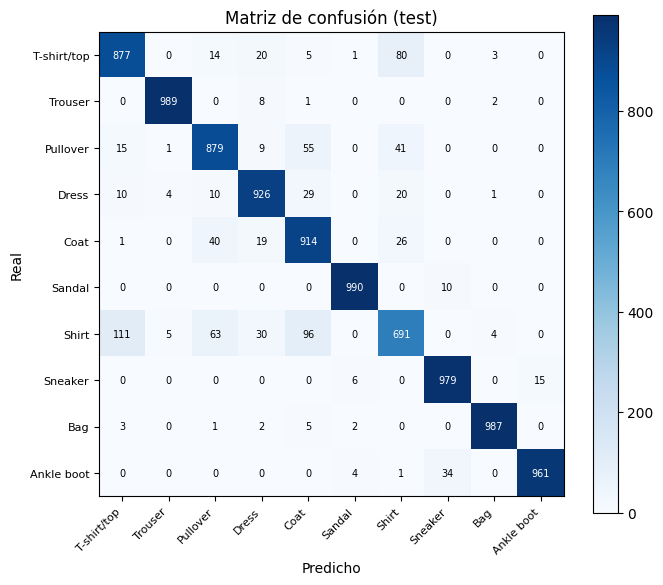

Pares que más se confunden:
  Shirt        -> T-shirt/top : 111 casos
  Shirt        -> Coat        : 96 casos
  T-shirt/top  -> Shirt       : 80 casos
  Shirt        -> Pullover    : 63 casos
  Pullover     -> Coat        : 55 casos


In [12]:
# Precisión, recall y f1 por clase
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap='Blues')
plt.title('Matriz de confusión (test)')
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha='right', fontsize=8)
plt.yticks(range(10), class_names, fontsize=8)
plt.xlabel('Predicho')
plt.ylabel('Real')

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=7)

plt.tight_layout()
plt.show()

# Los 5 pares (real -> predicho) que más se confunden
cm_sin_diagonal = cm.copy()
np.fill_diagonal(cm_sin_diagonal, 0)
pares = np.dstack(np.unravel_index(np.argsort(cm_sin_diagonal.ravel())[::-1], cm.shape))[0][:5]

print("Pares que más se confunden:")
for real, pred in pares:
    print(f"  {class_names[real]:<12} -> {class_names[pred]:<12}: {cm[real, pred]} casos")

---

## A. Sobre la arquitectura

**1. ¿Cuántas capas entrenables tiene tu modelo?**

**4 capas entrenables.** En el `model.summary()` las únicas capas que tienen parámetros son:

| Capa | Parámetros |
|---|---|
| `conv2d` (Conv2D, 32 filtros) | 320 |
| `conv2d_1` (Conv2D, 64 filtros) | 18.496 |
| `dense` (Dense, 128 neuronas) | 401.536 |
| `dense_1` (Dense, 10 neuronas) | 1.290 |

Las capas `MaxPooling2D`, `Dropout` y `Flatten` aparecen con 0 parámetros: no aprenden nada, solo reorganizan o
descartan información. El pooling se queda con el máximo de cada región, el dropout apaga unidades al azar y el
flatten cambia la forma del tensor; ninguna de las tres tiene pesos que el entrenamiento pueda ajustar.

**2. ¿Cuál es la cantidad total de parámetros entrenables?**

**421.642 parámetros** (`Total params: 421.642`, con `Non-trainable params: 0`, así que todos son entrenables).

Algo para notar: la capa `Dense(128)` sola se lleva 401.536 parámetros, o sea el **95%** del total, mientras que las
dos convolucionales juntas usan menos de 19.000. Esto muestra la ventaja de las capas convolucionales: como el mismo
filtro de 3×3 se reutiliza en toda la imagen, con poquísimos parámetros cubren todo el campo visual. La capa densa,
en cambio, conecta cada una de sus 128 neuronas con los 3.136 valores que salen del `Flatten`.

**3. ¿Qué hace cada capa en tu modelo?**

- **Conv2D:** aplica filtros (kernels) de 3×3 que se deslizan por toda la imagen buscando un patrón. Es como pasar una
  plantilla transparente por encima de la foto: donde la región coincide con el patrón, la respuesta es alta; donde no
  coincide, es baja. Cada filtro genera su propio mapa de características. La primera Conv2D (32 filtros) detecta
  cosas simples —bordes, líneas horizontales y verticales—, y la segunda (64 filtros) combina esos bordes en formas y
  texturas más complejas (una manga, una suela, una costura). Los filtros no se programan: arrancan con valores
  aleatorios (`glorot_uniform`) y se ajustan solos durante el entrenamiento. Como usamos `padding='same'`, la salida
  mantiene el mismo alto y ancho que la entrada.

- **MaxPooling2D (2×2):** divide cada mapa en regiones de 2×2 y se queda solo con el valor más grande de cada una.
  Reduce el tamaño a la mitad (28×28 → 14×14 y después 14×14 → 7×7), lo que abarata el cómputo y le da a la red
  tolerancia a que el objeto esté corrido unos píxeles. La idea es: "no importa el píxel exacto donde apareció el
  patrón, importa que apareció en esta zona".

- **Dropout:** durante el entrenamiento apaga al azar un porcentaje de las unidades (0.25 después de cada pooling y
  0.5 después de la capa densa). Así la red no puede depender siempre de las mismas neuronas y tiene que repartir el
  conocimiento, lo que reduce el sobreajuste. Al momento de predecir, el dropout se desactiva y funcionan todas.

- **Flatten:** convierte el bloque 3D de mapas de características (7×7×64) en un vector plano de 3.136 valores. Es
  solo un cambio de forma, no pierde ni agrega información: sirve para poder conectar la parte convolucional (que
  trabaja con estructura espacial) con las capas densas (que esperan vectores 1D).

- **Dense (última capa):** tiene 10 neuronas conectadas a todas las salidas de la capa anterior, con activación
  softmax. Es el "inspector final": junta toda la evidencia que recolectaron las capas anteriores y emite un puntaje
  para cada clase, que softmax transforma en probabilidades.

**4. ¿Por qué la última capa tiene 10 unidades y activación softmax?**

Tiene **10 unidades porque el problema tiene exactamente 10 clases** (T-shirt/top, Trouser, Pullover, Dress, Coat,
Sandal, Shirt, Sneaker, Bag, Ankle boot): una neurona de salida por clase. Si el dataset tuviera 5 prendas, serían
5 neuronas.

Usa **softmax** porque queremos una distribución de probabilidad: softmax toma los 10 puntajes crudos y los convierte
en 10 números entre 0 y 1 **que suman 1**. Así la salida se lee directo como "85% de probabilidad de que sea un
pullover, 10% de que sea un abrigo, …", y la predicción final es la clase con mayor probabilidad (`np.argmax`).
Además, softmax es la activación que se corresponde con la función de pérdida que usamos
(`sparse_categorical_crossentropy`), pensada para clasificación multiclase con etiquetas enteras 0..9.

## B. Sobre el entrenamiento

**5. Observación de las curvas de accuracy y loss**

- **¿El accuracy de entrenamiento aumenta con las épocas?** Sí, de forma sostenida: arranca en **0.7805** en la
  época 1 y termina en **0.9171** en la época 15. Sube rápido las primeras 4 épocas y después sigue subiendo más
  despacio, sin llegar a amesetarse del todo.

- **¿El accuracy de validación sigue la misma tendencia?** Sí, y se mantiene pegado al de entrenamiento durante
  todo el entrenamiento: va de **0.8613** a **0.9182**, con su mejor valor en **0.9208 (época 13)**. Las dos curvas
  suben juntas y nunca se separan.

- **¿Hay signos de sobreajuste?** **No, prácticamente no hay.** Los indicios que buscaríamos no aparecen:

  - El `val_loss` **baja durante todo el entrenamiento**, de 0.3732 a un mínimo de **0.2092 en la época 14**, y
    termina en 0.2166. No hay una subida sostenida al final, solo la fluctuación normal de la última época.
  - El accuracy de validación (**0.9182**) queda incluso **un poquito por encima** del de entrenamiento (0.9171),
    y lo mismo pasa con la loss (0.2166 de validación contra 0.2212 de entrenamiento). O sea que la brecha
    entrenamiento–validación es prácticamente cero.

  Esto último puede sorprender, pero tiene una explicación simple: el **dropout está activo durante el
  entrenamiento** (se apaga el 25% de las unidades después de cada pooling y el 50% en la capa densa), así que las
  métricas de entrenamiento se calculan con una red "mutilada". En validación, en cambio, el dropout se desactiva y
  trabaja la red completa, que anda un poco mejor. Los tres dropouts de esta arquitectura son justamente los que
  evitan el sobreajuste.

  La conclusión práctica es que **el modelo se quedó corto de entrenamiento más que pasado**: las dos curvas todavía
  venían subiendo en la época 15, así que entrenarlo más épocas probablemente lo mejoraría un poco más. El resultado
  final en test fue **91.56%**, coherente con el 91.82% de validación (sin sorpresas, o sea que generaliza bien).

**6. ¿Qué cambios harías para reducir el sobreajuste?**

Como en esta corrida el sobreajuste no apareció, estas son las herramientas que usaríamos si al entrenar más épocas
o al agrandar el modelo empezara a aparecer:

1. **Early stopping.** Cortar el entrenamiento cuando el `val_loss` deja de mejorar, con
   `EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)`. Automatiza el "pará acá" y además nos
   ahorra épocas de cómputo.

2. **Más dropout.** Subir el de los bloques convolucionales de 0.25 a 0.3–0.4, o el de la capa densa de 0.5 a 0.6.
   Es el ajuste más directo, porque ya está en la arquitectura.

3. **Data augmentation.** Generar variantes de las imágenes de entrenamiento (espejado horizontal, pequeñas
   rotaciones, traslaciones o zoom) con `layers.RandomFlip` / `RandomRotation` / `RandomZoom`. Es como mostrarle la
   misma prenda desde ángulos un poco distintos: la red aprende la forma general en vez del ejemplo puntual.

4. **Reducir la capacidad del modelo.** Achicar la `Dense` de 128 a 64 neuronas, o reemplazar el `Flatten` por un
   `GlobalAveragePooling2D`. Como el 95% de los parámetros está en esa capa densa, ahí es donde más se nota: con
   menos "memoria disponible" la red tiene que quedarse con los patrones generales.

5. **Regularización L2** (`kernel_regularizer=regularizers.l2(1e-4)`) en las capas densas, que penaliza los pesos
   grandes y suaviza el modelo.

## C. Sobre las predicciones

**7. Análisis de las predicciones incorrectas**

El modelo se equivocó en **844 de 10.000 imágenes de test** (8.44%).

- **¿Son difíciles incluso para un humano?** En buena medida, sí. Mirando las imágenes mal clasificadas, la mayoría
  son prendas de torso (remeras, camisas, pullovers, abrigos) que en 28×28 píxeles y en escala de grises quedan
  reducidas a "un rectángulo con dos mangas". Sin color, sin textura fina y sin botones visibles, distinguir una
  camisa de manga larga de un pullover liviano es difícil incluso mirándolo uno mismo.

- **¿Hay clases que se confundan mucho entre sí?** Sí, y la matriz de confusión lo muestra clarísimo. Los pares que
  más se confunden son:

  | Real → Predicho | Casos |
  |---|---|
  | Shirt → T-shirt/top | 95 |
  | Pullover → Coat | 84 |
  | T-shirt/top → Shirt | 79 |
  | Shirt → Coat | 77 |
  | Shirt → Pullover | 58 |

  Es decir, **los errores se concentran casi todos en el grupo {T-shirt/top, Pullover, Coat, Shirt}**. En cambio, el
  calzado (Sandal, Sneaker, Ankle boot), el pantalón (Trouser) y la cartera (Bag) casi no se confunden con nada,
  porque tienen siluetas únicas.

- **Posible razón:** es **similitud visual de la silueta**, no falta de datos (todas las clases tienen exactamente
  1.000 imágenes en test y 6.000 en entrenamiento, o sea que el dataset está perfectamente balanceado). Las cuatro
  prendas del grupo problemático comparten el mismo contorno —cuerpo rectangular con dos mangas— y lo que las
  diferencia en la vida real (el material, el color, los botones, el grosor de la tela) es justamente lo que se
  pierde al reducir la foto a 28×28 píxeles en blanco y negro.

**8. Precisión por clase**

Resultados del `classification_report`:

| Clase | Precision | Recall | F1-score |
|---|---|---|---|
| T-shirt/top | 0.875 | 0.868 | 0.871 |
| Trouser | 0.995 | 0.980 | **0.987** |
| Pullover | 0.883 | 0.840 | 0.861 |
| Dress | 0.886 | 0.934 | 0.909 |
| Coat | 0.819 | 0.899 | 0.857 |
| Sandal | 0.981 | 0.990 | 0.986 |
| Shirt | 0.784 | 0.731 | **0.757** |
| Sneaker | 0.959 | 0.977 | 0.968 |
| Bag | 0.992 | 0.979 | 0.985 |
| Ankle boot | 0.985 | 0.958 | 0.971 |
| **accuracy** | | | **0.916** |

- **Mejores clases:** Trouser (0.987), Sandal (0.986), Bag (0.985), Ankle boot (0.971) y Sneaker (0.968). Todas
  tienen una silueta muy característica y distinta del resto.
- **Peor clase por lejos:** **Shirt (0.757)**, seguida de Coat (0.857), Pullover (0.861) y T-shirt/top (0.871).

- **¿Coincide con lo observado visualmente?** Sí, totalmente. Las clases con peor f1-score son exactamente las cuatro
  que aparecen en los pares de confusión de la matriz, y las que mejor andan son las que visualmente no se parecen a
  ninguna otra. "Shirt" es el caso más claro: funciona como clase "intermedia" entre remera, pullover y abrigo, así
  que recibe errores de todas ellas y además pierde ejemplos propios hacia las tres (su recall es apenas 0.731, el
  más bajo de todos).

---

## D. Experimentación

**Variante elegida:** agregar un **tercer bloque `Conv2D + MaxPooling2D + Dropout`**, con progresión de filtros
32 → 64 → 128. El resto (padding, dropouts, capa densa, optimizador, épocas y batch size) queda igual que en el
modelo base, así la comparación es justa.

In [13]:
# -----------------------------------------------------------------------------
# 10. Modelo alternativo (model_v2): tres bloques convolucionales
# -----------------------------------------------------------------------------

tf.keras.utils.set_random_seed(42)

model_v2 = models.Sequential([
    # Bloque 1
    layers.Conv2D(32, (3, 3), activation='relu',
                  padding='same', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),          # 28x28 -> 14x14
    layers.Dropout(0.25),

    # Bloque 2
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),          # 14x14 -> 7x7
    layers.Dropout(0.25),

    # Bloque 3 (el agregado)
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),          # 7x7 -> 3x3
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model_v2.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241,546 (943.54 KB)

 Trainable params: 241,546 (943.54 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model_v2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_v2 = model_v2.fit(
    x_train, y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

test_loss_v2, test_acc_v2 = model_v2.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy (modelo base):       {test_acc:.4f}")
print(f"Test accuracy (modelo modificado): {test_acc_v2:.4f}")
print(f"Diferencia: {(test_acc_v2 - test_acc) * 100:+.2f} puntos porcentuales")

Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.7435 - loss: 0.6929 - val_accuracy: 0.8470 - val_loss: 0.4010
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8445 - loss: 0.4307 - val_accuracy: 0.8753 - val_loss: 0.3184
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8645 - loss: 0.3747 - val_accuracy: 0.8863 - val_loss: 0.2891
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8782 - loss: 0.3370 - val_accuracy: 0.9010 - val_loss: 0.2660
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8859 - loss: 0.3155 - val_accuracy: 0.9077 - val_loss: 0.2439
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8922 - loss: 0.2969 - val_accuracy: 0.9092 - val_loss: 0.2414
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8956 - loss: 0.2865 - val_accuracy: 0.9102 - val_loss: 0.2405
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8997 - loss: 0.2742 - val_accuracy: 

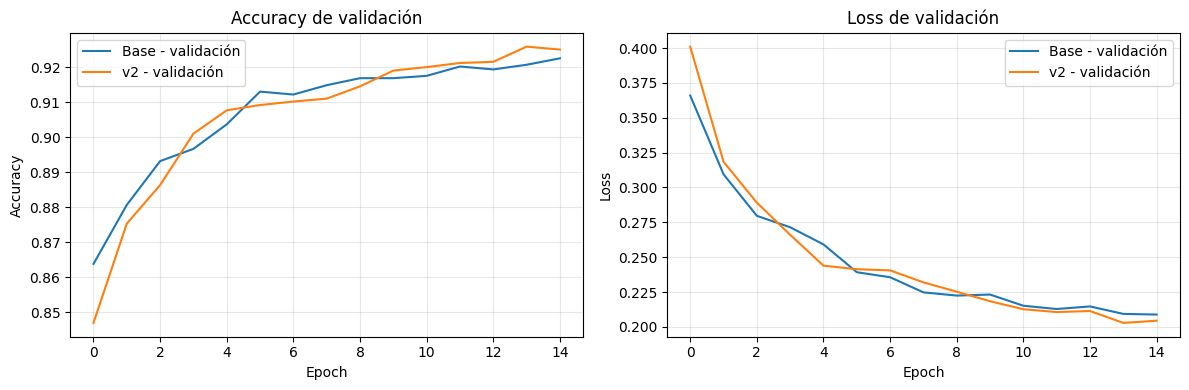

Parámetros modelo base: 421,642
Parámetros model_v2:    241,546
Menor val_loss base: 0.2089 (época 15)
Menor val_loss v2:   0.2029 (época 14)
Accuracy final entrenamiento - base: 0.9175 | v2: 0.9132


In [15]:
# Comparación de curvas: modelo base vs model_v2
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['val_accuracy'], label='Base - validación')
plt.plot(history_v2.history['val_accuracy'], label='v2 - validación')
plt.title('Accuracy de validación')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history['val_loss'], label='Base - validación')
plt.plot(history_v2.history['val_loss'], label='v2 - validación')
plt.title('Loss de validación')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Parámetros modelo base: {model.count_params():,}")
print(f"Parámetros model_v2:    {model_v2.count_params():,}")
print(f"Menor val_loss base: {min(history.history['val_loss']):.4f}"
      f" (época {int(np.argmin(history.history['val_loss'])) + 1})")
print(f"Menor val_loss v2:   {min(history_v2.history['val_loss']):.4f}"
      f" (época {int(np.argmin(history_v2.history['val_loss'])) + 1})")
print(f"Accuracy final entrenamiento - base: {history.history['accuracy'][-1]:.4f}"
      f" | v2: {history_v2.history['accuracy'][-1]:.4f}")

## D. Respuestas sobre la experimentación

**9. Modificación de la arquitectura y comparación de resultados**

**Resumen de `model_v2`** (tres bloques convolucionales en vez de dos):

| Capa | Output Shape | Parámetros |
|---|---|---|
| conv2d_2 (Conv2D, 32) | (None, 28, 28, 32) | 320 |
| max_pooling2d_2 | (None, 14, 14, 32) | 0 |
| dropout_3 (0.25) | (None, 14, 14, 32) | 0 |
| conv2d_3 (Conv2D, 64) | (None, 14, 14, 64) | 18.496 |
| max_pooling2d_3 | (None, 7, 7, 64) | 0 |
| dropout_4 (0.25) | (None, 7, 7, 64) | 0 |
| conv2d_4 (Conv2D, 128) | (None, 7, 7, 128) | 73.856 |
| max_pooling2d_4 | (None, 3, 3, 128) | 0 |
| dropout_5 (0.25) | (None, 3, 3, 128) | 0 |
| flatten_1 | (None, 1152) | 0 |
| dense_2 (Dense, 128) | (None, 128) | 147.584 |
| dropout_6 (0.5) | (None, 128) | 0 |
| dense_3 (Dense, 10) | (None, 10) | 1.290 |

**Total params: 241.546** (todos entrenables).

**Comparación:**

| | Modelo base | model_v2 |
|---|---|---|
| Bloques convolucionales | 2 | 3 |
| Capas entrenables | 4 | 5 |
| Parámetros | 421.642 | **241.546** |
| **Accuracy en test** | 0.9156 | **0.9186** |
| Mejor val_loss | 0.2092 (época 14) | **0.2047 (época 15)** |
| Accuracy final entrenamiento | 0.9171 | 0.9163 |
| Tiempo por época | ≈19 ms/step | ≈27 ms/step |

**Comentario:** el modelo modificado quedó **apenas mejor**: pasó de 91.56% a **91.86%** en test, o sea
**+0.30 puntos porcentuales** (unas 30 imágenes más bien clasificadas de las 10.000). También mejoró un poco el
`val_loss` mínimo (0.2047 contra 0.2092).

Lo más interesante no es la mejora en sí, sino que la consiguió **con casi la mitad de parámetros** (241.546 contra
421.642). La explicación está en el `Flatten`: en el modelo base el vector que entra a la capa densa tiene
7×7×64 = 3.136 valores, mientras que con el tercer bloque queda en 3×3×128 = 1.152. Al ser un vector más chico, la
`Dense(128)` pasa de 401.536 a 147.584 parámetros. O sea que el modelo con tres bloques está **mejor balanceado**:
gasta más en la parte convolucional (que es la que realmente extrae patrones) y mucho menos en la capa densa.

Ahora, siendo honestos con el resultado: **+0.30 puntos es una diferencia muy chica**, del orden de lo que puede
cambiar entre dos corridas por la aleatoriedad de la inicialización de los filtros y del dropout. No alcanza para
afirmar con seguridad que una arquitectura es mejor que la otra; para eso habría que entrenar varias veces cada una y
comparar promedios. Lo que sí se puede afirmar con confianza es que `model_v2` **logra lo mismo con casi la mitad de
parámetros**, y eso sí es una ventaja real.

Además, `model_v2` tarda bastante más por época (≈27 ms/step contra ≈19 ms/step), porque el tercer bloque agrega
cómputo aunque tenga menos pesos. Así que la elección entre uno y otro depende de qué se priorice: tamaño del modelo
o velocidad de entrenamiento.

Por último, **ninguno de los dos muestra sobreajuste** al cabo de 15 épocas: en los dos casos el `val_loss` seguía
bajando al final. Esto refuerza lo que dijimos en la pregunta 6: el próximo paso más prometedor no es agrandar el
modelo, sino **entrenar más épocas con early stopping** y sumar **data augmentation**, porque el techo acá se lo pone
la ambigüedad propia del dataset (camisa / remera / pullover / abrigo en 28×28 y en escala de grises) más que la
capacidad de la red.